# Topics over Time (ToT)

#### Author information

- **Name:** Jaeseong Choe

- **email address:** cjssoote@gmail.com

- **GitHub:** https://github.com/sorrychoe

- **Personal Webpage:** https://jaeseongchoe.vercel.app/

## Part 1. Brief background of methodology

### Overview

- **Topics over Time (ToT) is an extension of LDA that incorporates time as an additional observed variable, modeling how the relevance of topics changes over time.**

### Situation Before ToT

- While LDA can model topics, they do not explicitly model the relationship between the occurrence of topics and time.

### Why ToT Was Introduced

- ToT was introduced from the paper "Topics over Time: A Non-Markov Continuous-Time Model of Topical
Trends." of Wang, X., & McCallum, A. (2006).

- ToT adds time as an observed variable and models the dependency between topic relevance and time.

### Use Cases

- ToT can be used in studying historical trends, such as tracking the popularity of certain subjects over decades.

## Part 2. Key concept of methodology

### Key Concept

- ToT adds time as an observed variable and incorporates it into the generative process of topic modeling.
  

### Generative Process

ToT generates both the words and timestamps for each document, modeling time as a continuous variable. The generative process is:

1. **Topic Distribution for Document**:
   - For each document $d$, draw a topic distribution $\theta_d$ from a Dirichlet:
   $$
   \theta_d | \alpha \sim \text{Dirichlet}(\alpha)
   $$

2. **Topic-Specific Word Generation**:
   - For each word $w_{di}$ in document $d$:
     - Draw a topic $z_{di}$ from $\theta_d$:
     $$
     z_{di} | \theta_d \sim \text{Multinomial}(\theta_d)
     $$
     - Draw a word $w_{di}$ from the topic-specific distribution $\phi_{z_{di}}$:
     $$
     w_{di} | z_{di}, \phi \sim \text{Multinomial}(\phi_{z_{di}})
     $$

3. **Topic-Specific Timestamp Generation**:
   - Draw a timestamp $t_{di}$ for the word from the topic's Beta distribution:
   $$
   t_{di} | z_{di}, \psi \sim \text{Beta}(\psi_{z_{di}})
   $$

![ToT_Graphic](./img/ToT_Graphic.png)

### Mathematical Representation

- **Word Distribution**: 
  Each word is generated from a multinomial distribution parameterized by $\phi_z$ for topic $z$:
  $$
  p(w | z, \phi_z) = \prod_{i=1}^V \phi_{zi}^{w_i}
  $$
  where $\phi_z$ is the multinomial distribution over words for topic $z$.

- **Timestamp Distribution**:
  The timestamp is modeled using a Beta distribution for each topic:
  $$
  p(t | z, \psi_z) = \frac{t^{\psi_{z1} - 1} (1 - t)^{\psi_{z2} - 1}}{B(\psi_{z1}, \psi_{z2})}
  $$
  where $B(\psi_{z1}, \psi_{z2})$ is the Beta function, and $\psi_z = (\psi_{z1}, \psi_{z2})$ parameterizes the Beta distribution.

### Inference

Inference in ToT uses **Gibbs sampling** for approximate posterior inference.

1. **Conditional Probability**:
   The conditional distribution for $z_{di}$ given words and timestamps is:
   $$
   P(z_{di} | w, t, z_{-di}, \alpha, \beta, \Psi) \propto (m_{d z_{di}} + \alpha_{z_{di}} - 1) \cdot \frac{n_{z_{di} w_{di}} + \beta_{w_{di}} - 1}{\sum_{v=1}^{V} (n_{z_{di} v} + \beta_v - 1)} \cdot p(t_{di} | \psi_{z_{di}})
   $$
   where $m_{d z_{di}}$ is the number of words in document $d$ assigned to topic $z_{di}$, and $n_{z_{di} w_{di}}$ is the number of words $w_{di}$ assigned to topic $z_{di}$.

2. **Beta Distribution Parameters**:
   The Beta distribution parameters are estimated via the method of moments:
   $$
   \psi_{z1} = t_z \left( \frac{t_z (1 - t_z)}{s_z^2} - 1 \right)
   $$
   $$
   \psi_{z2} = (1 - t_z) \left( \frac{t_z (1 - t_z)}{s_z^2} - 1 \right)
   $$
   where $t_z$ and $s_z^2$ are the sample mean and variance of timestamps for topic $z$.

### Strength

- ToT captures temporal trends in topic popularity.

- Time is treated as a continuous variable, so there is no need to choose a time-slice size as in DTM.

- ToT makes no Markov assumption, so a topic can appear, disappear, and reappear without being split in two.

- ToT can predict the timestamp of a document from its words alone.

### Weakness

- The meaning (word distribution) of each topic is constant over time. ToT tracks how often a topic occurs, not how its vocabulary changes.

- Each topic has a single Beta distribution over time, so a topic is assumed to have one rise and one fall.

- The balance between the text and the time likelihood must be tuned. The paper notes that this hyper-parameter is quite sensitive.

- Until recently, neither Python nor R had a library that reproduces the ToT model as the formula implemented in the paper.

## Part 3. Example

### Before Sample code

- No library implemented ToT exactly as the formula stated in the paper, in either Python or R.

- For this reason, I implemented the R package `topicovertime`, which fits ToT by collapsed Gibbs sampling in C++, following the paper.

- In this sample code, I use the `topicovertime` package of R, so all codes are written in R (like the STM notebook).

### Precautions

- If you re-execute the code, there may be a slight difference in the result.

- Of course, the difference in the number or content of the topic will not be significant due to the seed number, but the order of the topics may change.

In [1]:
# import librarys
library(topicovertime) # for ToT
library(tidyverse) # for Data preprocessing(dplyr, tidyr), visualization(ggplot2) & use pipeline operator(magrittr)
library(tidytext) # for Text preprocessing
library(showtext) # for set the Korean font
library(readxl) # for load excel data

font_add_google(name = "Nanum Gothic", family = "nanumgothic") # korean font setup
showtext_auto()
options(repr.plot.width = 12, repr.plot.height = 7)

# set the seed number
set.seed(42)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


Loading required package: sysfonts



Loading required package: showtextdb



In [2]:
# data load
# The data is related to Handong University, 
# which was reported in major Korean daily newspapers from January 1995 to September 2024.
df <- read_xlsx("data/NewsResult_19950101-20240930.xlsx")

# ToT uses the publication date itself as a continuous timestamp.
# Unlike DTM, there is no need to cut the data into time slices.
df$Date <- as.Date(df$일자, format = "%Y%m%d")
df$doc_id <- seq_len(nrow(df))

In [3]:
# data preprocessing
# split the comma-separated keywords into one word per row
tokens <- df |>
  select(doc_id, 키워드) |>
  separate_longer_delim(키워드, ",") |>
  rename(word = 키워드) |>
  filter(word != "")

# same vocabulary filter as the DTM notebook (min_cf = 5, rm_top = 10)
word_freq <- tokens |> count(word, sort = TRUE)
vocab <- word_freq |> filter(n >= 5) |> slice(-(1:10)) |> pull(word)

# make the document-term matrix
dtm <- tokens |>
  filter(word %in% vocab) |>
  count(doc_id, word) |>
  cast_sparse(doc_id, word, n)

dates <- df$Date[as.integer(rownames(dtm))]

cat("Num docs:", nrow(dtm), ", Num Vocabs:", ncol(dtm), ", Total Words:", sum(dtm), "\n")
cat("Removed top 10 words:", head(word_freq$word, 10), "\n")

Num docs: 8051 , Num Vocabs: 27098 , Total Words: 1656995 


Removed top 10 words: 미국 대학 북한 교수 한동대 한국 대통령 정부 교육 중국 


### Balancing the text and the time

- In ToT, every word token carries the timestamp of its document. A news article in this data has about 200 tokens, so the weight of the time likelihood against the words (`time_weight`) changes the result a lot. The paper also notes that this hyper-parameter is quite sensitive.

- I compared three settings, training on 90% of the articles and predicting the dates of the other 10% (numbers below are from a separate comparison run with `n_iter = 200`; there, always predicting the median date gave a median error of 4.49 years).

| time_weight | topic words | time spread of topics (sd) | median error of date prediction |
|---|---|---|---|
| `1` (the Gibbs sampling formula of the paper) | mixed (e.g. church and diplomacy in one topic) | 0.4 ~ 3.4 years | 3.45 years |
| `"inverse_length"` ($1/N_d$, suggested in the paper) | coherent | 3.6 ~ 7.6 years | 4.70 years (worse than baseline) |
| **`0.3`** | **coherent** | 1.0 ~ 7.8 years | **3.89 years** |

- With `1`, time overwhelms the words and each topic becomes a narrow time period. With `"inverse_length"`, the timestamp is counted only once per article, so time barely shapes the topics. **`0.3` keeps the topics coherent while still using the time information**, so I use it here.

- ToT has no built-in function for choosing K, so I use **K = 7**, the value chosen in the STM notebook, for comparison.

In [4]:
# define & train the model
tot_model <- tot(dtm, dates,
                 k = 7,
                 n_iter = 300,
                 time_weight = 0.3)

tot_model

Topics over Time model
  topics: 7, documents: 8051, vocabulary: 27098
  iterations: 300, alpha: 7.142857, beta: 0.1, time_weight: 0.3
  time range: 1995-01-04 to 2024-09-29

In [5]:
# words per Topics
terms(tot_model, 10)

Topic1,Topic2,Topic3,Topic4,Topic5,Topic6,Topic7
서울,정치,교회,트럼프,학생,대표,지역
전형,인권,목사,협상,총장,포항,지원
모집,외교,하나님,회담,학교,지진,사업
반영,국민,사람,위원장,학생들,회장,기업
지원,일본,기독교,정상,졸업,서울,선정
연세대,상황,사랑,남북,영어,지역,포항
고려대,지적,생각,외교,평가,발생,산업
수능,사건,기도,한반도,프로그램,피해,협력
선발,주장,사회,대북,운영,이사장,글로벌
서울대,국가,선교,장관,국제,장애인,세계


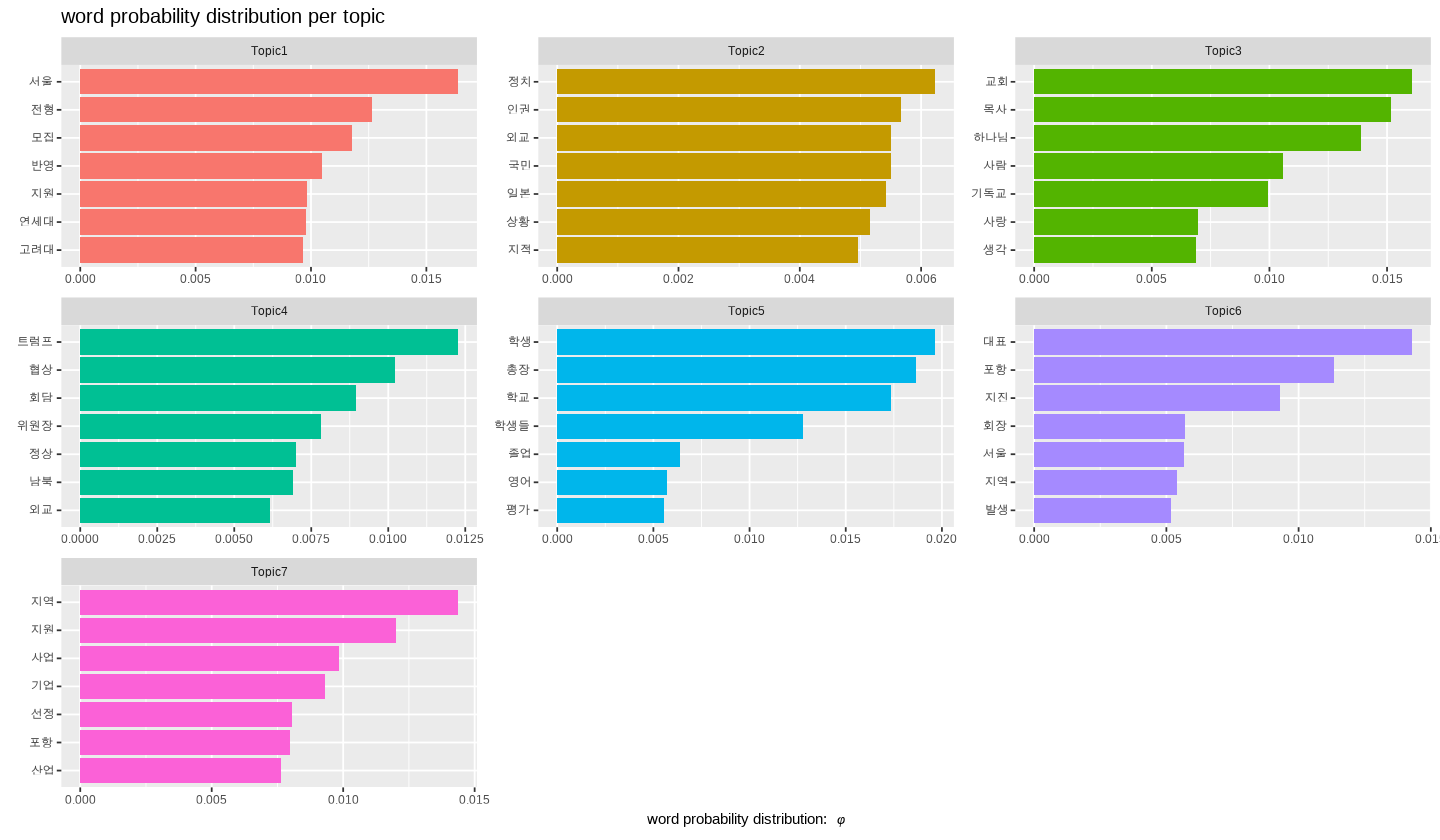

In [6]:
# Tidy the result into a data.frame
# Extract the phi value (word probability distribution of each topic)
td_beta <- as_tibble(t(tot_model$phi), rownames = "term") |>
  pivot_longer(-term, names_to = "topic", values_to = "beta")

# visualization of topic's value
td_beta |>
  group_by(topic) |>
  slice_max(beta, n = 7) |>
  ungroup() |>
  ggplot(aes(x = beta, 
             y = reorder_within(term, beta, topic),
             fill = topic)) +
  geom_col(show.legend = F) +
  scale_y_reordered() +
  facet_wrap(~topic, scales = "free") +
  labs(x = expression("word probability distribution: "~phi), y = NULL,
       title = "word probability distribution per topic") +
  theme(plot.title = element_text(size = 15))

In [7]:
# Beta distribution over time per topic (psi)
# psi is estimated on the normalized time scale (0 to 1), so convert it back to dates.
date_range <- range(dates)
span <- as.numeric(diff(date_range))
psi <- tot_model$psi

topic_labels <- apply(terms(tot_model, 3), 2, paste, collapse = ", ")
topic_labels <- paste0(names(topic_labels), ": ", topic_labels)

topic_period <- tibble(
  topic = topic_labels,
  shape1 = psi[, 1],
  shape2 = psi[, 2],
  mean_date = date_range[1] + span * shape1 / (shape1 + shape2),
  sd_years = sqrt(shape1 * shape2 / ((shape1 + shape2)^2 * (shape1 + shape2 + 1))) * span / 365.25,
  share = tot_model$topic_size / sum(tot_model$topic_size)
) |>
  arrange(mean_date)

topic_period

topic,shape1,shape2,mean_date,sd_years,share
<chr>,<dbl>,<dbl>,<date>,<dbl>,<dbl>
"Topic1: 서울, 전형, 모집",1.431153,2.338695,2006-04-19,6.607441,0.1030456
"Topic5: 학생, 총장, 학교",1.625853,1.335944,2011-05-02,7.433836,0.1268670
"Topic6: 대표, 포항, 지진",2.307602,1.382668,2013-08-08,6.646024,0.1067613
"Topic3: 교회, 목사, 하나님",1.704514,1.000000,2013-10-01,7.458046,0.1498520
"Topic2: 정치, 인권, 외교",2.936760,1.334186,2015-06-16,6.002797,0.1812848
"Topic4: 트럼프, 협상, 회담",88.850328,19.172522,2019-06-20,1.088114,0.2104677
"Topic7: 지역, 지원, 사업",5.383141,1.000000,2020-02-01,3.977795,0.1217216


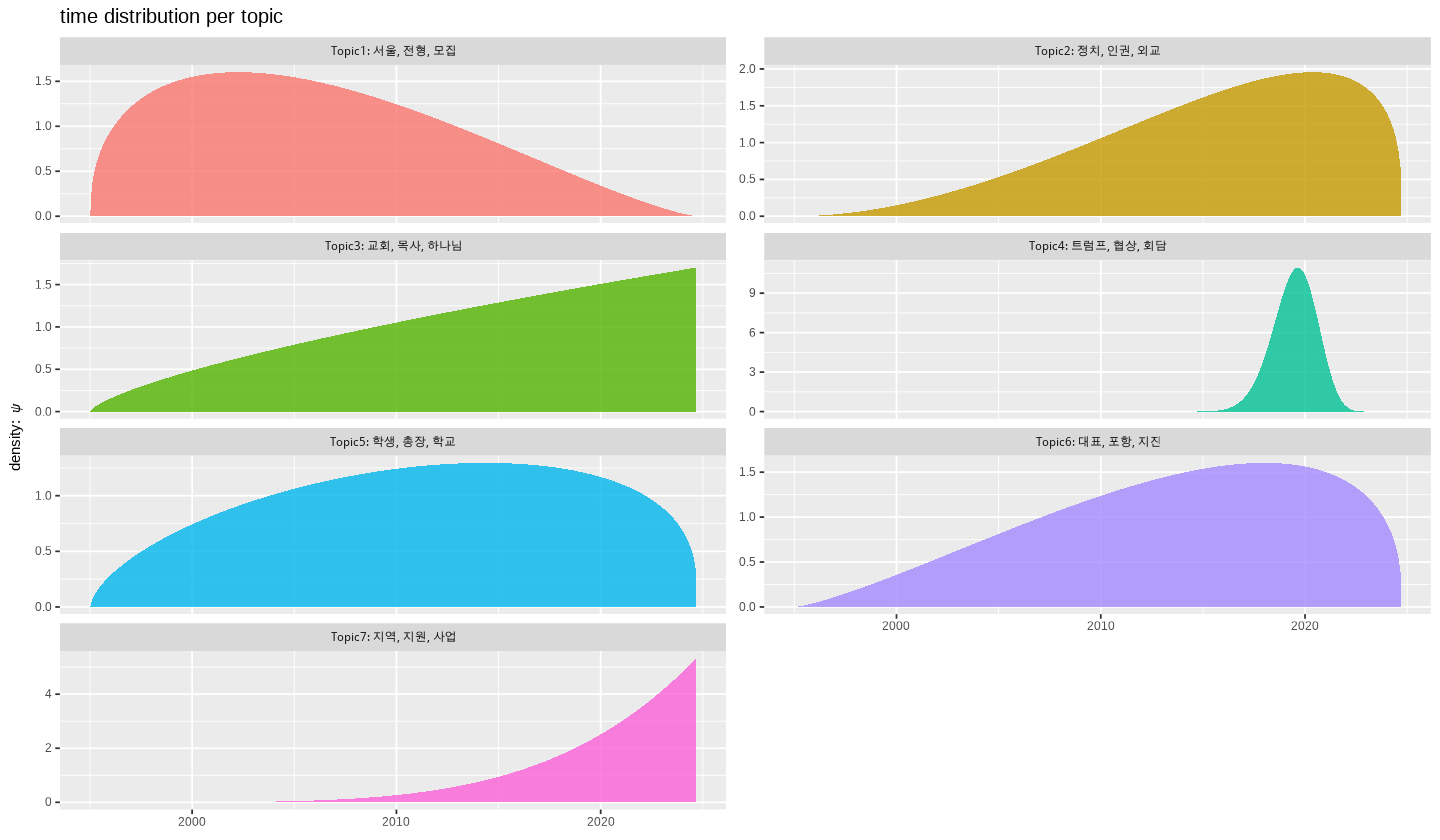

In [8]:
# show the time distribution of each topic
date_grid <- seq(date_range[1], date_range[2], by = "month")

td_psi <- map_dfr(seq_len(tot_model$k), function(k) {
  tibble(topic = topic_labels[k],
         date = date_grid,
         density = dbeta(as.numeric(date_grid - date_range[1]) / span, psi[k, 1], psi[k, 2]))
})

td_psi |>
  ggplot(aes(x = date, y = density, fill = topic)) +
  geom_area(show.legend = F, alpha = 0.8) +
  facet_wrap(~topic, ncol = 2, scales = "free_y") +
  labs(x = NULL, y = expression("density: "~psi),
       title = "time distribution per topic") +
  theme(plot.title = element_text(size = 15))

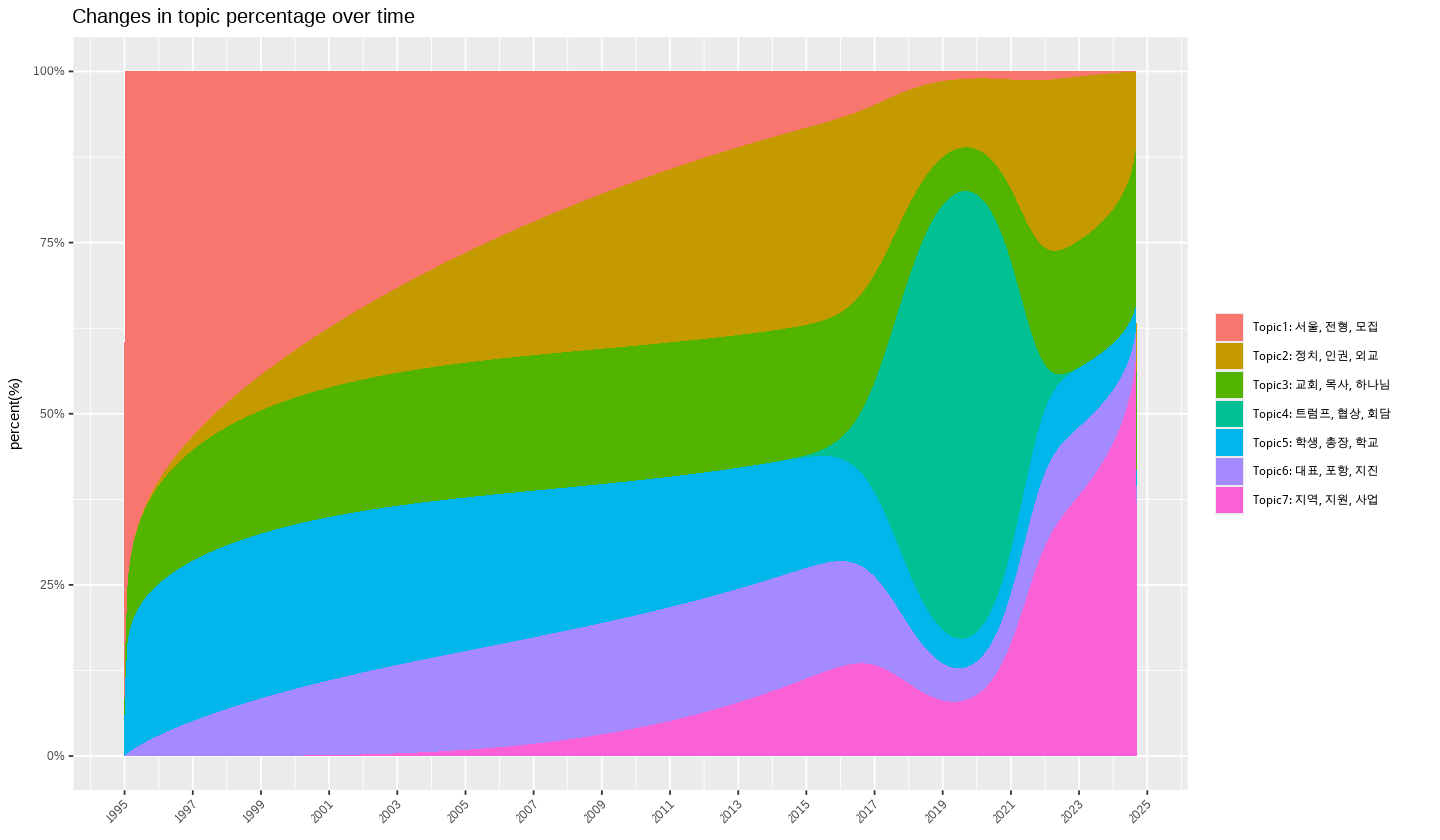

In [9]:
# Changes in topic percentage over time: P(topic | time)
td_trend <- topic_time(tot_model, date_grid) |>
  as_tibble() |>
  setNames(topic_labels) |>
  mutate(date = date_grid) |>
  pivot_longer(-date, names_to = "topic", values_to = "prob")

td_trend |>
  ggplot(aes(x = date, y = prob, fill = topic)) +
  geom_area() +
  scale_y_continuous(labels = scales::percent) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y") +
  labs(x = NULL, y = "percent(%)", fill = NULL,
       title = "Changes in topic percentage over time") +
  theme(plot.title = element_text(size = 15),
        axis.text.x = element_text(angle = 45, hjust = 1))

### Predicting the timestamp

- Because each topic has its own distribution over time, ToT can predict when a document was written from its words alone.

- The predicted timestamp is the one that maximizes $\prod_{i=1}^{N_d} p(t | \psi_{z_i})$, as in the paper.

- To check this fairly, I train the model on 90% of the articles and predict the dates of the remaining 10%.

In [10]:
# split the data into train(90%) & test(10%)
test_idx <- sample(nrow(dtm), round(nrow(dtm) * 0.1))

train_model <- tot(dtm[-test_idx, ], dates[-test_idx],
                   k = 7,
                   n_iter = 300,
                   time_weight = 0.3)

# predict the date of unseen articles
pred_date <- predict(train_model, dtm[test_idx, ], type = "time")

pred_result <- tibble(actual = dates[test_idx], predicted = pred_date) |>
  mutate(error_years = abs(as.numeric(predicted - actual)) / 365.25)

cat("correlation:", round(cor(as.numeric(pred_result$actual), as.numeric(pred_result$predicted)), 3), "\n")
cat("median absolute error (years):", round(median(pred_result$error_years), 2), "\n")
cat("baseline, always predicting the median date (years):",
    round(median(abs(as.numeric(dates[test_idx] - median(dates[-test_idx]))) / 365.25), 2), "\n")

correlation: 0.406 


median absolute error (years): 3.73 


baseline, always predicting the median date (years): 4.84 


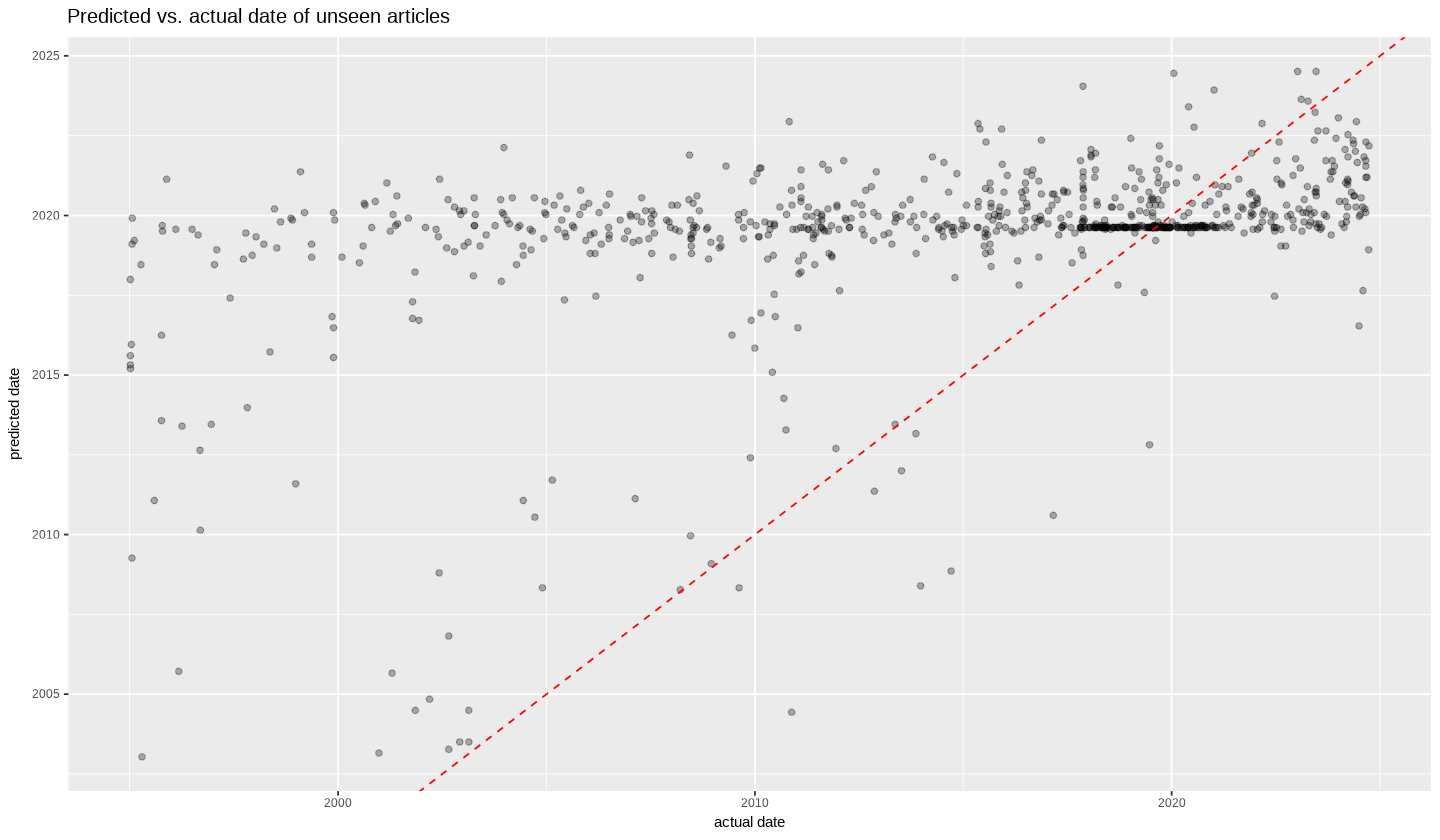

In [11]:
# show result as a plot
pred_result |>
  ggplot(aes(x = actual, y = predicted)) +
  geom_point(alpha = 0.3) +
  geom_abline(slope = 1, intercept = 0, colour = "red", linetype = "dashed") +
  labs(x = "actual date", y = "predicted date",
       title = "Predicted vs. actual date of unseen articles") +
  theme(plot.title = element_text(size = 15))